# Subsequent elbow injury in MLB pitchers: fastball-velocity EWMA-CUSUM charts (v2)

**What changed from v1.** v1 compared "did the chart ever signal" between cases and controls, but cases
are monitored only until their subsequent elbow IL while controls are monitored to the end of the season,
so controls had more chances to signal by chance. v2:

1. **Matches monitoring length**: each case is compared with controls' charts cut at the same number of
   games since return (Section 9), plus a threshold-free matched AUC by λ.
2. **Adds a per-game analysis**: does an alarm after a game raise the chance of an elbow IL within the
   next few appearances (Section 10)?
3. **Widens the h grid** to 0.05–5 and selects on matched **Youden** (the NBA grid's best point is still
   reported).
4. **Runs pooled and per-fastball SDs side by side**, so short reliever outings count for less.
5. **Reports starters and relievers separately** (Section 11).
6. **Leaves the held-out season off** (`RUN_HELDOUT = False`) until the design is final.

Outputs go to `data/elbow_ewma_cusum_v2/`, so v1's outputs are untouched.

**Question.** Among pitchers who return from an **initial elbow IL placement**, can a game-by-game
control chart on fastball velocity flag the pitchers who go on to a **subsequent elbow IL placement**
the same season, before it happens?

**Cohort and outcome**

| | Definition |
|---|---|
| Unit | One pitcher-season with an elbow IL placement (the first elbow placement that season), first return by August 31, at least 5 post-return appearances |
| Case | A later IL placement that season, after the return, for the elbow (first non-COVID placement after the return is an elbow placement) |
| Control | No later elbow placement that season. If the next placement is for something else (shoulder, oblique, ...), the pitcher stays a control and his chart **stops at that IL date** |
| "Elbow" | Elbow, UCL / Tommy John, ulnar nerve, flexor / pronator, forearm, epicondyle, olecranon, valgus, internal brace; "non-throwing" excluded |

**Statistics monitored, one value per game**, from the pitcher's primary fastball (four-seam or sinker,
whichever he threw more before the injury), in games with at least 8 primary fastballs:

* **CV** = 100 × SD / mean of fastball velocity in that game. Hypothesis: CV **rises** before an elbow injury → **upper-sided** chart.
* **Mean velocity** in that game. Hypothesis: velocity **drops** → **lower-sided** chart (the same direction as the NBA study).

**Chart.** The EWMA-CUSUM from the NBA study. For the lower-sided chart (as in the NBA paper):

$$\text{PCI}_{\text{lower},j} = \frac{x_j - \text{LSL}}{\sigma_0},\quad \text{LSL} = \mu_0 - 2\sigma_0,\qquad
c_j = \min\{0,\ \lambda(\text{PCI}_{\text{lower},j} - 2) + (1-\lambda)c_{j-1}\},\quad \text{signal if } c_j < -h.$$

The upper-sided chart for CV is the mirror image:

$$\text{PCI}_{\text{upper},j} = \frac{\text{USL} - x_j}{\sigma_0},\quad \text{USL} = \mu_0 + 2\sigma_0,\qquad
c_j = \max\{0,\ \lambda(2 - \text{PCI}_{\text{upper},j}) + (1-\lambda)c_{j-1}\},\quad \text{signal if } c_j > h.$$

Both reduce to the same recursion on $z_j = (x_j-\mu_0)/\sigma_0$, with the sign flipped for the lower side.

**Baseline (Approach B of the NBA study).** $\mu_0$ is the pitcher's mean over his games in the 365 days
before the initial elbow injury, shrunk toward the grand mean with the empirical-Bayes weight
$k = \sigma^2_{\text{within}}/\sigma^2_{\text{between}}$ (one-way random-effects ANOVA, Henderson's Method I);
$\sigma_0$ is the pooled within-pitcher SD. The grand mean, $k$ and $\sigma_0$ are estimated from the
**training seasons only**.

**Evaluation.** As in the NBA study — (λ, h) grid on the training seasons, a block-bootstrap false-alarm
check, ROC frontier and AUC, then one application of the frozen model to the held-out season — but with
cases and controls compared over the same number of monitored games (see "What changed"). Every monitored
game comes before the subsequent IL date, so every signal is a warning ahead of it.

**Data.** The injury workbook (`MLB Injuries Raw Data.xlsx`), the Chadwick register for FanGraphs → MLBAM
IDs, and Baseball Savant pitch-by-pitch data. Everything is cached in `data/`; the Statcast cache from the
replication notebook (`data/statcast/`) is reused where it covers the needed dates, and only missing date
ranges are downloaded.

Run top to bottom. All rules are in the Settings cell.

## 1. Settings

In [1]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "elbow_ewma_cusum_v2"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = WORKSPACE / "MLB Injuries Raw Data.xlsx"
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
TRAIN_SEASONS = [2021, 2022, 2023, 2024]
TEST_SEASON = 2025                  # held out: used once, in Section 13
RUN_HELDOUT = False                 # keep False until the design is final
SEASONS = TRAIN_SEASONS + [TEST_SEASON]

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
ELBOW_PATTERN = re.compile(
    r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|valgus|internal brace",
    flags=re.IGNORECASE,
)
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial elbow injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
CV_FIRST_N = None                   # e.g. 20 = use only his first 20 primary fastballs in each game
SIGMA_MODES = ["pooled", "per_fb"]  # pooled SD (NBA study) and SD scaled by 1/sqrt(fastballs in the game)

METRICS = {
    "cv":   {"label": "Fastball velocity CV (%)",     "side": "upper"},   # signal on a rise
    "velo": {"label": "Mean fastball velocity (mph)", "side": "lower"},   # signal on a drop
}

# ---- Chart grid (NBA study) ----
LAMBDA_GRID = np.round(np.arange(0.45, 0.951, 0.10), 2)           # 0.45 ... 0.95
LAMBDA_GRID_LOW = np.round(np.arange(0.05, 0.351, 0.10), 2)       # sensitivity check: 0.05 ... 0.35
H_GRID_NBA = np.round(np.arange(0.05, 0.501, 0.05), 2)            # NBA grid, 0.05 ... 0.50 (reported for reference)
H_GRID_WIDE = np.round(np.r_[np.arange(0.05, 0.501, 0.05), np.arange(0.75, 5.001, 0.25)], 2)  # selection grid
# Selection: highest matched Youden on the training seasons (accuracy favours never signalling at ~17% cases)
N_PERM = 500                        # label shuffles for the permutation test
HAZARD_K = 3                        # per-game analysis: elbow IL within the next 3 appearances
N_BOOT = 1000                       # pitcher-clustered bootstrap resamples
MATCH_WITHIN_ROLE = True            # compare each case only with controls of the same role
SHRINK_BY_ROLE = True               # shrink each pitcher toward his role's mean (starter / reliever / mixed)
MIN_UNITS_ROLE_FIT = 10             # a role needs >= 10 training units for its own fit (else league-wide)

# ---- Block-bootstrap false-alarm check ----
N_NULL_SEQUENCES = 5000
BLOCK_LEN = 3
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Training seasons:", TRAIN_SEASONS, "| held-out season:", TEST_SEASON)
print("Outputs:", OUT_DIR)

Training seasons: [2021, 2022, 2023, 2024] | held-out season: 2025
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/elbow_ewma_cusum_v2


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as elbow /
not elbow and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [2]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["pkey"] = injuries["FanGraphs_ID"].where(injuries["FanGraphs_ID"].notna(),
                                                  "name:" + injuries["Name"].astype(str))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
injuries["is_elbow"] = (injuries["Injury"].str.contains(ELBOW_PATTERN)
                        & ~injuries["Injury"].str.contains("non-throwing", case=False))
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      elbow_rows=("is_elbow", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_elbow", "IL rows"], ascending=[False, False]))
classification_review.to_csv(OUT_DIR / "elbow_classification_review.csv", index=False)
print("Elbow descriptions:")
with pd.option_context("display.max_rows", 200):
    display(classification_review.loc[classification_review["is_elbow"]])
print("Most common non-elbow descriptions (full list in elbow_classification_review.csv):")
display(classification_review.loc[~classification_review["is_elbow"]].head(25))

,pitcher_IL_rows,elbow_rows,covid_rows,missing_fangraphs_id
Season,,,,
2021,687,153,130,0
2022,559,147,10,0
2023,502,158,2,0
2024,483,175,2,0
2025,458,163,0,0


Elbow descriptions:


,is_elbow,Injury,IL rows
449,True,Tommy John surgery,249
380,True,Elbow inflammation,126
443,True,Strained forearm,65
372,True,Elbow discomfort,28
438,True,Sprained elbow,28
423,True,Forearm inflammation,23
439,True,Strained elbow,21
402,True,Elbow surgery (internal brace),20
440,True,Strained elbow flexor,18
415,True,Flexor tendon surgery,16


Most common non-elbow descriptions (full list in elbow_classification_review.csv):


,is_elbow,Injury,IL rows
219,False,Shoulder inflammation,149
299,False,Strained shoulder,109
293,False,Strained oblique,106
281,False,Strained hamstring,91
217,False,Shoulder impingement,72
280,False,Strained groin,70
356,False,Undisclosed,63
286,False,Strained lat,59
288,False,Strained lower back,44
273,False,Strained calf,34


## 3. Cohort: initial elbow IL placement → subsequent elbow IL placement

For each pitcher-season, the **initial** placement is his first elbow placement of that season. The
**next** non-COVID placement after his return decides the outcome: elbow → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [3]:
elbow = injuries.loc[injuries["is_elbow"] & ~injuries["is_covid"]]
units = (elbow.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an elbow IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_elbow"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_elbow = later.loc[later["is_elbow"]].groupby(["pkey", "Season"]).size().rename("n_later_elbow")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_elbow"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_elbow": "next_is_elbow"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_elbow, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_elbow"] = units["next_is_elbow"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_elbow"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent elbow IL", "control: stopped at non-elbow IL"],
    default="control: no later IL")

n_elbow_after_other = int(((units["case"] == 0) & units["n_later_elbow"].notna()).sum())
print("Controls whose next placement was non-elbow but who had an elbow placement later that season:",
      n_elbow_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-elbow but who had an elbow placement later that season: 3 (kept as controls, as specified)


outcome,case: subsequent elbow IL,control: no later IL,control: stopped at non-elbow IL,All
Season,,,,
2021,13,30,14,57
2022,10,25,14,49
2023,9,29,9,47
2024,11,36,13,60
2025,6,28,17,51
All,49,148,67,264


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial elbow
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [4]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None)
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
262,Dylan File,2021,sa3004197
263,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 262


In [5]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (1 failures)
100 windows (6 failures)
150 windows (11 failures)
200 windows (17 failures)
250 windows (19 failures)


,Name,Season,mlbam,error
0,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
1,Justin Topa,2022,623437,"NotImplementedError(""strftime not yet supporte..."
2,John Means,2024,607644,"NotImplementedError(""strftime not yet supporte..."
3,Erik Swanson,2025,657024,"NotImplementedError(""strftime not yet supporte..."
4,Austin Davis,2021,656354,"NotImplementedError(""strftime not yet supporte..."
5,Michael Kopech,2025,656629,"NotImplementedError(""strftime not yet supporte..."
6,Peter Lambert,2022,663567,"NotImplementedError(""strftime not yet supporte..."
7,Zac Gallen,2021,668678,"NotImplementedError(""strftime not yet supporte..."
8,Matt Foster,2024,641582,"NotImplementedError(""strftime not yet supporte..."
9,Jonathan Loáisiga,2025,642528,"NotImplementedError(""strftime not yet supporte..."


Pitches: 391,863 | pitchers: 218


In [6]:
# Elbow descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial elbow descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial elbow descriptions naming a side: 0; side differs from the throwing arm: 0


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.

In [7]:
def per_game(game_pitches, primary):
    """Mean, SD and CV of the primary fastball, one row per game."""
    fb = game_pitches.loc[(game_pitches["pitch_type"] == primary) & game_pitches["release_speed"].notna()]
    if CV_FIRST_N:
        fb = fb.groupby("game_pk", sort=False).head(CV_FIRST_N)
    g = (fb.groupby("game_pk")
           .agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std"))
           .reset_index().sort_values(["game_date", "game_pk"]))
    g["cv"] = 100 * g["sd"] / g["velo"]
    return g.loc[g["n_fb"] >= MIN_FB_GAME].reset_index(drop=True)


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    pre_games = pre.groupby("game_pk")["inning"].min()
    ref_games = pre_games if len(pre_games) else monitored_raw.groupby("game_pk")["inning"].min()
    start_share = (ref_games == 1).mean() if len(ref_games) else np.nan
    role = ("unknown" if np.isnan(start_share) else "starter" if start_share >= 0.6
            else "reliever" if start_share <= 0.2 else "mixed")
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    unit_data[row["uid"]] = {
        "primary": primary,
        "role": role,
        "baseline": per_game(pre, primary),
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = np.where(units["Season"].isin(TRAIN_SEASONS), "train", "test")
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["role"] = units["uid"].map(lambda u: unit_data[u]["role"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
display(pd.crosstab([units["split"], units["role"]], units["case"].map({1: "case", 0: "control"})))
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 49
Dropped: no Statcast pitches: 14
Dropped: no monitored game with enough fastballs: 7
Dropped: no four-seam or sinker: 5


,step,pitcher-seasons
0,Pitcher-seasons with an elbow IL placement,732
1,... with a return date,599
2,... return on or after the IL date,599
3,... first return by 08-31,264
4,... with an MLBAM ID,262
5,"... with Statcast data, >= 5 post-return appea...",187


units  cases  controls_stopped_at_other_IL  \
split Season                                               
test  2025       37      5                            13   
train 2021       38      6                            10   
      2022       33      7                            10   
      2023       34      6                             7   
      2024       45      6                            10   

              median_baseline_games  no_baseline_games  median_monitored_games  
split Season                                                                    
test  2025                     16.0                  2                     7.0  
train 2021                     15.0                  1                     8.0  
      2022                     15.0                  0                    11.0  
      2023                     24.0                  0                     8.0  
      2024                     19.0                  4                     8.0

case            case  control
split role                   
test  mixed        1        0
      reliever     2       14
      starter      2       18
train mixed        1        7
      reliever    15       65
      starter      9       53

## 6. Baselines (Approach B: empirical-Bayes shrinkage, training seasons only)

For each statistic, the grand mean $G$, the pooled within-pitcher variance $\sigma^2_w$ (ANOVA
$SS_W/df_W$) and the between-pitcher variance $\sigma^2_b$ (Henderson's Method I) come from the
**baseline games of training-season units**. Each unit then gets

$$\mu_0 = \frac{n_i \bar x_i + k G}{n_i + k},\qquad k = \sigma^2_w / \sigma^2_b,$$

where $n_i$ and $\bar x_i$ are his own baseline games. A unit with no baseline games gets $\mu_0 = G$.
Held-out units use the same frozen $G$, $k$ and $\sigma_0$.

**Shrink toward the role mean** (`SHRINK_BY_ROLE = True`). Starters' game CV is naturally higher than
relievers' (fatigue fade over 90 pitches adds spread). When between-pitcher variance is small, shrinkage
pulls everyone toward one league mean, so starters sit above their baseline in every game, and charts
alarm on role rather than injury. Fitting $G$, $k$ and $\sigma$ separately for starters, relievers and
mixed-role pitchers (each with at least `MIN_UNITS_ROLE_FIT` training units) removes that.

**Two versions of the game SD, run side by side** (each statistic × SD version is one "chart"):

* `pooled` — one $\sigma_0$ for every game (the NBA study).
* `per_fb` — each game's SD depends on how many primary fastballs he threw:
  $\sigma_j = \sqrt{\tau^2 + s^2/n_{fb,j}}$. $\tau^2$ is game-to-game variation that more fastballs do
  not remove (a pitcher's level shifts from day to day); $s^2/n_{fb}$ is the part that does. Both are
  estimated from training baseline games by regressing squared within-pitcher deviations on $1/n_{fb}$.
  A 9-fastball reliever outing therefore counts for less than a 50-fastball start, without treating a
  long start as nearly noise-free.

In [8]:
def fit_shrinkage(frames, value):
    """Henderson Method I on baseline games. frames: list of per-unit baseline DataFrames."""
    groups = [f for f in frames if len(f) >= 1]
    y = [f[value].to_numpy(float) for f in groups]
    w = [f["n_fb"].to_numpy(float) for f in groups]
    n = np.array([len(v) for v in y], float)
    N, a = n.sum(), len(y)
    grand = np.concatenate(y).mean()
    means = np.array([v.mean() for v in y])
    df_w = N - a
    ms_w = sum(((v - v.mean()) ** 2).sum() for v in y) / df_w
    ms_b = (n * (means - grand) ** 2).sum() / (a - 1)
    n0 = (N - (n ** 2).sum() / N) / (a - 1)
    var_b = max((ms_b - ms_w) / n0, 0.0)
    k = ms_w / var_b if var_b > 0 else np.inf
    # Per-game variance model: Var(game value) = tau^2 + s^2 / n_fb  (a game-to-game part that does not
    # shrink with more fastballs, plus a part that does). Least squares of squared within-pitcher
    # deviations (df-corrected) on 1 / n_fb, both components kept >= 0.
    r2 = np.concatenate([((v - v.mean()) ** 2) * len(v) / (len(v) - 1) for v in y if len(v) >= 2])
    inv_n = np.concatenate([1 / wi for v, wi in zip(y, w) if len(v) >= 2])
    X = np.column_stack([np.ones_like(inv_n), inv_n])
    tau2, s2 = np.linalg.lstsq(X, r2, rcond=None)[0]
    if s2 < 0:
        tau2, s2 = r2.mean(), 0.0
    elif tau2 < 0:
        tau2, s2 = 0.0, (r2 * inv_n).sum() / (inv_n ** 2).sum()
    return {"grand_mean": grand, "sigma_w": np.sqrt(ms_w), "sigma_b": np.sqrt(var_b), "k": k,
            "tau": np.sqrt(tau2), "s_per_fb": np.sqrt(s2), "units": a, "games": int(N)}


def shrunk_mean(baseline, value, fit):
    n_i = len(baseline)
    if n_i == 0 or not np.isfinite(fit["k"]):
        return fit["grand_mean"]
    return (n_i * baseline[value].mean() + fit["k"] * fit["grand_mean"]) / (n_i + fit["k"])


toy = [pd.DataFrame({"x": [1.0, 2.0, 3.0], "n_fb": 10}), pd.DataFrame({"x": [3.0, 2.0, 1.0], "n_fb": 10})]
toy_fit = fit_shrinkage(toy, "x")
assert toy_fit["k"] == np.inf and abs(shrunk_mean(toy[0], "x", toy_fit) - 2.0) < 1e-12
assert abs(toy_fit["sigma_w"] - 1.0) < 1e-12

CHARTS = {f"{m}|{mode}": {"stat": m, "mode": mode,
                          "label": f"{METRICS[m]['label']} — {'pooled SD' if mode == 'pooled' else 'per-fastball SD'}"}
          for m in METRICS for mode in SIGMA_MODES}

train_uids = units.loc[units["split"] == "train", "uid"].tolist()
test_uids = units.loc[units["split"] == "test", "uid"].tolist()
fits_all = {m: fit_shrinkage([unit_data[u]["baseline"] for u in train_uids], m) for m in METRICS}
fits_role = {}
if SHRINK_BY_ROLE:
    for role in ["starter", "reliever", "mixed"]:
        ru = [u for u in train_uids if unit_data[u]["role"] == role and len(unit_data[u]["baseline"])]
        if len(ru) >= MIN_UNITS_ROLE_FIT:
            fits_role[role] = {m: fit_shrinkage([unit_data[u]["baseline"] for u in ru], m) for m in METRICS}


def fit_for(u, m):
    """Role-specific fit if available (SHRINK_BY_ROLE), otherwise the league-wide fit."""
    return fits_role.get(unit_data[u]["role"], fits_all)[m]


fit_table = pd.concat({"all": pd.DataFrame(fits_all).T,
                       **{r: pd.DataFrame(f).T for r, f in fits_role.items()}}, names=["fit", "statistic"])
fit_table.to_csv(OUT_DIR / "baseline_fits.csv")
display(fit_table.round(4))
print("Roles with their own fit:", list(fits_role) or "none (league-wide fit for everyone)")


def game_sigma(frame, fit, mode):
    if mode == "per_fb":
        return np.sqrt(fit["tau"] ** 2 + fit["s_per_fb"] ** 2 / frame["n_fb"].to_numpy(float))
    return np.full(len(frame), fit["sigma_w"])


for u in units["uid"]:
    d = unit_data[u]
    d["mu0"], d["z"], d["dev"], d["baseline_dev"], d["sigma"] = {}, {}, {}, {}, {}
    for m, spec in METRICS.items():
        fit = fit_for(u, m)
        mu0 = shrunk_mean(d["baseline"], m, fit)
        d["mu0"][m] = mu0
        d["z"][m] = (d["monitored"][m].to_numpy(float) - mu0) / fit["sigma_w"]   # descriptive (pooled)
    for key, c in CHARTS.items():
        m, fit = c["stat"], fit_for(u, c["stat"])
        sign = 1.0 if METRICS[m]["side"] == "upper" else -1.0
        sig = game_sigma(d["monitored"], fit, c["mode"])
        d["sigma"][key] = sig
        d["dev"][key] = sign * (d["monitored"][m].to_numpy(float) - d["mu0"][m]) / sig
        b = d["baseline"]
        d["baseline_dev"][key] = sign * (b[m].to_numpy(float) - d["mu0"][m]) / game_sigma(b, fit, c["mode"])
print(f"Baselines frozen on {len(train_uids)} training units. Charts:", list(CHARTS))

grand_mean  sigma_w  sigma_b       k     tau  s_per_fb  \
fit      statistic                                                           
all      cv             0.9613   0.2407   0.2502  0.9254  0.2388    0.1157   
         velo          94.6658   0.7773   2.4317  0.1022  0.7316    1.0291   
starter  cv             1.1242   0.2604   0.2165  1.4471  0.2362    0.5855   
         velo          93.2275   0.7588   2.2653  0.1122  0.5364    2.8765   
reliever cv             0.8186   0.2248   0.1936  1.3476  0.0741    0.7099   
         velo          95.8502   0.7659   1.9445  0.1551  0.7547    0.4227   

                    units   games  
fit      statistic                 
all      cv         145.0  2731.0  
         velo       145.0  2731.0  
starter  cv          60.0  1160.0  
         velo        60.0  1160.0  
reliever cv          77.0  1385.0  
         velo        77.0  1385.0

Roles with their own fit: ['starter', 'reliever']
Baselines frozen on 150 training units. Charts: ['cv|pooled', 'cv|per_fb', 'velo|pooled', 'velo|per_fb']


## 7. Does either statistic move before a subsequent elbow injury?

Before any chart: the standardized value $z = (x-\mu_0)/\sigma_0$ of each case's monitored games, by how
many games before the subsequent elbow IL placement they came (1 = his final game), against the average
monitored game of the controls (grey band). CV is expected to sit **above** the band, velocity **below**
it. Training seasons only. This figure does not depend on chart settings or on how long anyone was
monitored, so it is the plainest answer to the question.

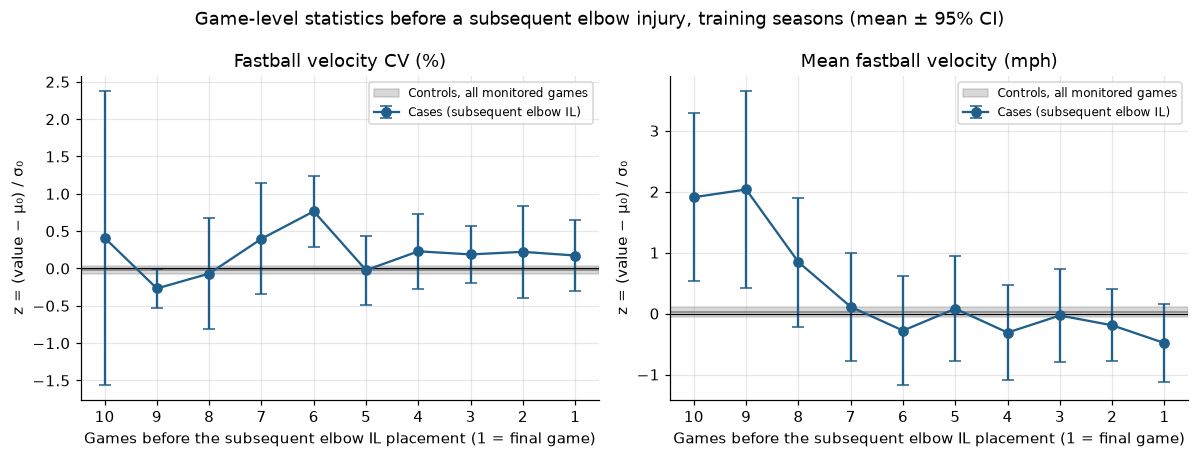

In [9]:
GAMES_BACK = 10
fig, axes = plt.subplots(1, len(METRICS), figsize=(5.5 * len(METRICS), 4.2), squeeze=False)
descriptive_rows = []
train_cases = [u for u in train_uids if units.at[u, "case"] == 1]
train_ctrls = [u for u in train_uids if units.at[u, "case"] == 0]
for ax, (m, spec) in zip(axes[0], METRICS.items()):
    ctrl = np.concatenate([unit_data[u]["z"][m] for u in train_ctrls] or [[]])
    case_rows = [{"games_before_IL": back, "z": value}
                 for u in train_cases
                 for back, value in enumerate(unit_data[u]["z"][m][::-1][:GAMES_BACK], start=1)]
    cz = pd.DataFrame(case_rows, columns=["games_before_IL", "z"])
    s = cz.groupby("games_before_IL")["z"].agg(["mean", "std", "count"]).reindex(range(1, GAMES_BACK + 1))
    s["half"] = 1.96 * s["std"] / np.sqrt(s["count"])
    if len(ctrl):
        c_mean, c_half = ctrl.mean(), 1.96 * ctrl.std(ddof=1) / np.sqrt(len(ctrl))
        ax.axhspan(c_mean - c_half, c_mean + c_half, color="grey", alpha=0.3, label="Controls, all monitored games")
        ax.axhline(c_mean, color="grey", lw=1)
    ax.errorbar(s.index, s["mean"], yerr=s["half"], fmt="o-", color="#1f5f8b", capsize=4,
                label="Cases (subsequent elbow IL)")
    ax.axhline(0, color="black", lw=0.8)
    ax.invert_xaxis()
    ax.set_xticks(range(1, GAMES_BACK + 1))
    ax.set_xlabel("Games before the subsequent elbow IL placement (1 = final game)")
    ax.set_ylabel("z = (value − μ₀) / σ₀")
    ax.set_title(spec["label"])
    ax.legend(fontsize=8)
    descriptive_rows.append(s.assign(statistic=m).reset_index())
fig.suptitle("Game-level statistics before a subsequent elbow injury, training seasons (mean ± 95% CI)")
fig.tight_layout()
save(fig, "E1_statistics_before_subsequent_elbow_IL")
pd.concat(descriptive_rows).to_csv(OUT_DIR / "descriptive_games_before_IL.csv", index=False)

## 8. The monitoring-length problem

A case's chart stops at his subsequent elbow IL date; a control's runs to the end of the season (or to a
non-elbow IL). If controls are watched for more games, they get more chances to signal by chance, and an
"any signal" comparison is biased against the chart. If the per-game false-alarm chance is $p$, the
chance of at least one alarm in $L$ games is $1-(1-p)^L$.

In [10]:
exposure = (units.loc[units["split"] == "train"]
                 .assign(group=lambda d: np.where(d["case"] == 1, "case", "control"))
                 .groupby(["group", "role"])["monitored_games"]
                 .describe()[["count", "25%", "50%", "75%", "mean"]])
exposure.to_csv(OUT_DIR / "monitored_games_by_group.csv")
display(exposure.round(1))

count  25%   50%   75%  mean
group   role                                  
case    mixed       1.0  7.0   7.0   7.0   7.0
        reliever   15.0  3.5   6.0   8.0   6.0
        starter     9.0  2.0   6.0   8.0   5.9
control mixed       7.0  6.0   9.0  18.0  11.9
        reliever   65.0  4.0   8.0  17.0  11.3
        starter    53.0  7.0  12.0  17.0  12.6

## 9. EWMA-CUSUM charts, matched on monitoring length (training seasons)

**Chart.** The same one-sided EWMA-CUSUM as the NBA study, checked below against its lower-sided formula.

**Matched evaluation.** A case's chart is read over his $m$ monitored games. Each control is read over
his **first $m$ monitored games since return** (controls with fewer than $m$ games are not used for that
case, as in the pitch-count matching of the replication notebook), and only controls in the **same role**
(starter / reliever / mixed) are used, because starters and relievers differ in games per season and in
how noisy their game statistics are. So both groups are judged on the same
exposure, at the same point after return.

* **Sensitivity**: share of cases whose chart signals at any of their $m$ games.
* **Matched specificity**: for each case, the share of eligible (same-length, same-role) controls that do **not** signal within
  their first $m$ games, averaged over cases (each case counts once).
* **Matched AUC** (threshold-free, for each λ): each case's chart peak against the eligible controls'
  peaks over their first $m$ games; the share of controls it beats (ties ½), averaged over cases. 0.5 =
  chance. 95% intervals resample **pitchers** (all of a pitcher's units together).

The unmatched ("any signal over the whole series") numbers are kept alongside for comparison.

In [11]:
def ewma_cusum(dev, lam):
    """One-sided EWMA-CUSUM on deviations signed toward the hypothesis (signal if path > h)."""
    path = np.empty(len(dev))
    prev = 0.0
    for j, x in enumerate(dev):
        prev = max(0.0, lam * x + (1 - lam) * prev)
        path[j] = prev
    return path


def nba_lower(values, mu0, sigma0, lam):
    """The NBA study's statistic, as written in its notebook (for the check below)."""
    stat, prev = [], 0.0
    for v in values:
        pci = (v - (mu0 - 2 * sigma0)) / sigma0
        prev = min(lam * (pci - 2) + (1 - lam) * prev, 0.0)
        stat.append(prev)
    return np.array(stat)


rng_check = np.random.default_rng(1)
vals = rng_check.normal(93, 1, 50)
for lam in (0.05, 0.45, 0.95):
    np.testing.assert_allclose(-nba_lower(vals, 93.2, 0.8, lam),
                               ewma_cusum(-(vals - 93.2) / 0.8, lam), atol=1e-12)
print("Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).")


def peaks(uids, key, lam):
    """Running maximum of the chart for each unit: peaks[u][m-1] = highest value over the first m games."""
    return {u: np.maximum.accumulate(ewma_cusum(unit_data[u]["dev"][key], lam)) for u in uids}


def pair_matrices(uids, key, lam, role=None, P=None, labels=None):
    """S (case beats control), V (valid pair) for cases vs controls cut to the case's length.
    P: precomputed peaks (optional); labels: {uid: 0/1} overriding units['case'] (for permutations)."""
    lab = labels if labels is not None else {u: int(units.at[u, "case"]) for u in uids}
    cases = [u for u in uids if lab[u] == 1 and (role is None or units.at[u, "role"] == role)]
    ctrls = [u for u in uids if lab[u] == 0 and (role is None or units.at[u, "role"] == role)]
    if not cases or not ctrls:
        return cases, ctrls, None, None, None
    P = P if P is not None else peaks(cases + ctrls, key, lam)
    L = max(len(P[u]) for u in ctrls)
    C = np.full((len(ctrls), L), np.nan)
    for j, u in enumerate(ctrls):
        C[j, :len(P[u])] = P[u]
    case_peak = np.array([P[u][-1] for u in cases])
    case_len = np.array([len(P[u]) for u in cases])
    col = np.full((len(cases), len(ctrls)), np.nan)
    ok = case_len <= L
    col[ok] = C[:, case_len[ok] - 1].T                      # control peaks over the case's first m games
    V = ~np.isnan(col)
    if MATCH_WITHIN_ROLE:
        V &= (np.array([units.at[u, "role"] for u in cases])[:, None]
              == np.array([units.at[u, "role"] for u in ctrls])[None, :])
    S = np.where(V, (case_peak[:, None] > col) + 0.5 * (case_peak[:, None] == col), 0.0)
    return cases, ctrls, case_peak, col, (S, V)


def matched_grid(uids, key, lambdas, hs, role=None):
    hs = np.asarray(hs, float)
    rows = []
    for lam in lambdas:
        cases, ctrls, case_peak, col, SV = pair_matrices(uids, key, lam, role)
        if SV is None:
            continue
        V = SV[1]
        use = V.any(axis=1)
        for h in hs:
            sens = (case_peak[use] > h).mean()
            with np.errstate(invalid="ignore"):
                spec_i = np.nanmean(np.where(V, col <= h, np.nan), axis=1)
            rows.append({"chart": key, "lambda": lam, "h": h, "cases": int(use.sum()), "controls": len(ctrls),
                         "Sensitivity": sens, "Matched_specificity": np.nanmean(spec_i[use])})
    out = pd.DataFrame(rows)
    if len(out):
        out["Youden"] = out["Sensitivity"] + out["Matched_specificity"] - 1
    return out


def cluster_codes(cases, ctrls):
    ids = np.array([units.at[u, "pkey"] for u in cases + ctrls])
    groups, codes = np.unique(ids, return_inverse=True)
    return len(groups), codes[:len(cases)], codes[len(cases):]


def eq_auc(S, V, w_i, w_h):
    SV = S * V
    denom = V @ w_h
    with np.errstate(invalid="ignore", divide="ignore"):
        placement = (SV @ w_h) / denom
    ok = (denom > 0) & (w_i > 0)
    return np.sum(w_i[ok] * placement[ok]) / np.sum(w_i[ok]) if ok.any() else np.nan


def matched_auc(uids, key, lam, role=None, n_boot=None):
    cases, ctrls, _, _, SV = pair_matrices(uids, key, lam, role)
    if SV is None:
        return {"cases": len(cases), "controls": len(ctrls), "AUC": np.nan, "lower95": np.nan, "upper95": np.nan}
    S, V = SV
    n_groups, ci, hi = cluster_codes(cases, ctrls)
    est = eq_auc(S, V, np.ones(len(cases)), np.ones(len(ctrls)))
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(n_boot or N_BOOT):
        t = np.bincount(rng.integers(n_groups, size=n_groups), minlength=n_groups).astype(float)
        draws.append(eq_auc(S, V, t[ci], t[hi]))
    lo, up = np.nanpercentile(draws, [2.5, 97.5])
    return {"cases": int(V.any(axis=1).sum()), "controls": len(ctrls), "AUC": est, "lower95": lo, "upper95": up}


auc_rows = []
for key in CHARTS:
    for lam in np.r_[LAMBDA_GRID_LOW, LAMBDA_GRID]:
        auc_rows.append({"chart": key, "lambda": lam, **matched_auc(train_uids, key, lam)})
train_auc = pd.DataFrame(auc_rows)
train_auc.to_csv(OUT_DIR / "train_matched_auc.csv", index=False)
print(f"Training units: {len(train_uids)} ({len(train_cases)} cases, {len(train_ctrls)} controls)")
print("Matched AUC by chart and λ (threshold-free; 0.5 = chance):")
display(train_auc.pivot(index="lambda", columns="chart", values="AUC").round(3))
display(train_auc.sort_values("AUC", ascending=False).groupby("chart").head(1).round(3))

Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).
Training units: 150 (25 cases, 125 controls)
Matched AUC by chart and λ (threshold-free; 0.5 = chance):


chart,cv|per_fb,cv|pooled,velo|per_fb,velo|pooled
lambda,,,,
0.05,0.519,0.517,0.511,0.515
0.15,0.512,0.506,0.507,0.511
0.25,0.507,0.505,0.505,0.510
0.35,0.508,0.505,0.505,0.509
0.45,0.512,0.508,0.502,0.506
0.55,0.514,0.508,0.497,0.503
0.65,0.513,0.505,0.497,0.500
0.75,0.516,0.509,0.496,0.505
0.85,0.515,0.510,0.503,0.508


,chart,lambda,cases,controls,AUC,lower95,upper95
10,cv|per_fb,0.05,25,125,0.519,0.385,0.653
0,cv|pooled,0.05,25,125,0.517,0.382,0.650
20,velo|pooled,0.05,25,125,0.515,0.375,0.664
30,velo|per_fb,0.05,25,125,0.511,0.373,0.653


### Permutation test (the main significance test)

Case / control labels are shuffled **within season × role** (so each shuffle keeps the same number of
cases per season and role), and the matched AUC is recomputed at every λ. Each shuffle's **best** λ is
kept, so the test accounts for having picked the best λ. Shuffling also absorbs any small built-in tilt
of the matched comparison (on simulated data with no signal, the shuffled matched AUC for CV averaged
about 0.52 rather than 0.50). p = share of shuffles whose best AUC is at least the observed best.

Shuffling units assumes units are independent. A pitcher who appears in several seasons is not: if his
true level sits off the shrunk baseline, every one of his units looks the same way. The test is therefore
also run on **one unit per pitcher** (his earliest training season). If the two p-values disagree, trust
the one-unit-per-pitcher version.

In [12]:
ALL_LAMBDAS = np.r_[LAMBDA_GRID_LOW, LAMBDA_GRID]
true_labels = {u: int(units.at[u, "case"]) for u in train_uids}
# One unit per pitcher (his earliest training season): removes repeat pitchers, whose persistent
# offsets from the shrunk baseline make unit-level shuffling too optimistic.
first_unit = (units.loc[train_uids].sort_values("Season").groupby("pkey")["uid"].first().tolist())
n_repeat = int((units.loc[train_uids].groupby("pkey").size() > 1).sum())
print(f"Training pitchers with more than one unit: {n_repeat} "
      f"({len(train_uids)} units from {units.loc[train_uids, 'pkey'].nunique()} pitchers)")


def best_auc(P_by_lam, key, labels, uids):
    vals = []
    for lam in ALL_LAMBDAS:
        cases, ctrls, _, _, SV = pair_matrices(uids, key, lam, P=P_by_lam[lam], labels=labels)
        vals.append(eq_auc(SV[0], SV[1], np.ones(len(cases)), np.ones(len(ctrls))) if SV else np.nan)
    vals = np.array(vals, float)
    i = int(np.nanargmax(vals))
    return vals[i], ALL_LAMBDAS[i]


rng = np.random.default_rng(SEED)
perm_rows = []
for subset_name, subset in [("all units", train_uids), ("one unit per pitcher", first_unit)]:
  strata = units.loc[subset].groupby(["Season", "role"])["uid"].apply(list).tolist()
  for key in CHARTS:
    P_by_lam = {lam: peaks(subset, key, lam) for lam in ALL_LAMBDAS}
    observed, lam_best = best_auc(P_by_lam, key, true_labels, subset)
    null = []
    for _ in range(N_PERM):
        labels = {}
        for members in strata:
            labels.update(zip(members, rng.permutation([true_labels[u] for u in members])))
        null.append(best_auc(P_by_lam, key, labels, subset)[0])
    null = np.array(null)
    perm_rows.append({"units": subset_name, "n_units": len(subset),
                      "cases": int(sum(true_labels[u] for u in subset)),
                      "chart": key, "best_lambda": lam_best, "observed_best_AUC": observed,
                      "shuffled_best_AUC_mean": null.mean(), "shuffled_95th_pct": np.quantile(null, 0.95),
                      "p_value": (1 + (null >= observed).sum()) / (N_PERM + 1)})
perm_test = pd.DataFrame(perm_rows)
perm_test.to_csv(OUT_DIR / "train_permutation_test.csv", index=False)
display(perm_test.round(3))

Training pitchers with more than one unit: 14 (150 units from 136 pitchers)


,units,n_units,cases,chart,best_lambda,observed_best_AUC,shuffled_best_AUC_mean,shuffled_95th_pct,p_value
0,all units,150,25,cv|pooled,0.05,0.517,0.510,0.615,0.461
1,all units,150,25,cv|per_fb,0.05,0.519,0.513,0.604,0.471
2,all units,150,25,velo|pooled,0.05,0.515,0.595,0.707,0.876
3,all units,150,25,velo|per_fb,0.05,0.511,0.594,0.695,0.934
4,one unit per pitcher,136,24,cv|pooled,0.05,0.526,0.515,0.618,0.427
5,one unit per pitcher,136,24,cv|per_fb,0.05,0.534,0.521,0.617,0.429
6,one unit per pitcher,136,24,velo|pooled,0.05,0.531,0.590,0.696,0.836
7,one unit per pitcher,136,24,velo|per_fb,0.05,0.527,0.594,0.682,0.860


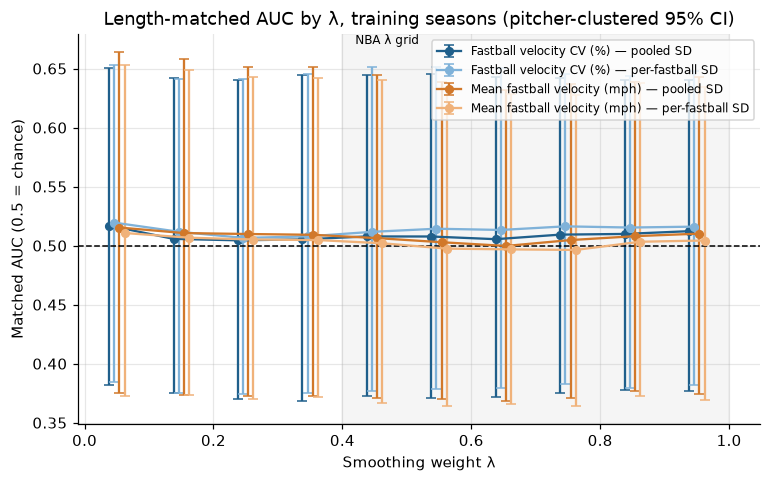

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = {"cv|pooled": "#1f5f8b", "cv|per_fb": "#7fb2d9", "velo|pooled": "#d1782a", "velo|per_fb": "#f0b27a"}
offsets = np.linspace(-0.012, 0.012, len(CHARTS))
for off, key in zip(offsets, CHARTS):
    d = train_auc.loc[train_auc["chart"] == key]
    ax.errorbar(d["lambda"] + off, d["AUC"], yerr=[d["AUC"] - d["lower95"], d["upper95"] - d["AUC"]],
                fmt="o-", capsize=3, ms=5, color=colors.get(key), label=CHARTS[key]["label"])
ax.axhline(0.5, ls="--", color="black", lw=1)
ax.axvspan(LAMBDA_GRID.min() - 0.05, LAMBDA_GRID.max() + 0.05, color="grey", alpha=0.08)
ax.text(LAMBDA_GRID.min() - 0.03, ax.get_ylim()[1], "NBA λ grid", va="top", fontsize=8)
ax.set_xlabel("Smoothing weight λ")
ax.set_ylabel("Matched AUC (0.5 = chance)")
ax.set_title("Length-matched AUC by λ, training seasons (pitcher-clustered 95% CI)")
ax.legend(fontsize=8)
save(fig, "E2_matched_auc_by_lambda")

### Matched sensitivity / specificity across (λ, h) and the selected setting

The h grid now runs from 0.05 to 5 (the NBA grid stops at 0.50, which on game-level velocity lets a single
ordinary bad game trip the chart). Selection: highest **matched Youden** on the training seasons (ties:
higher sensitivity, then larger h). The best point within the NBA grid (h ≤ 0.50) is shown for reference,
with the unmatched numbers at the same settings.

In [14]:
train_grid = pd.concat([matched_grid(train_uids, key, LAMBDA_GRID, H_GRID_WIDE) for key in CHARTS],
                       ignore_index=True)
train_grid.to_csv(OUT_DIR / "train_matched_grid.csv", index=False)


def unmatched(uids, key, lam, h):
    """Any signal over the whole monitored series (the original evaluation)."""
    sig = np.array([ewma_cusum(unit_data[u]["dev"][key], lam).max() > h for u in uids])
    case = np.array([units.at[u, "case"] == 1 for u in uids])
    return {"unmatched_sens": sig[case].mean() if case.any() else np.nan,
            "unmatched_spec": (~sig[~case]).mean() if (~case).any() else np.nan}


def pick(grid):
    ranked = grid.dropna(subset=["Youden"]).sort_values(["chart", "Youden", "Sensitivity", "h"],
                                                         ascending=[True, False, False, False])
    return ranked.groupby("chart").head(1).set_index("chart")


chosen = pick(train_grid)
nba_best = pick(train_grid.loc[train_grid["h"] <= H_GRID_NBA.max() + 1e-9])
summary_rows = []
for label, table in [("selected (wide h)", chosen), ("best within NBA grid", nba_best)]:
    for key, r in table.iterrows():
        summary_rows.append({"setting": label, "chart": key, "lambda": r["lambda"], "h": r["h"],
                             "Sensitivity": r["Sensitivity"], "Matched_specificity": r["Matched_specificity"],
                             "Youden": r["Youden"], **unmatched(train_uids, key, r["lambda"], r["h"])})
selection_table = pd.DataFrame(summary_rows)
selection_table.to_csv(OUT_DIR / "train_selected_settings.csv", index=False)
display(selection_table.round(3))
for key, r in chosen.iterrows():
    if r["h"] in (H_GRID_WIDE.min(), H_GRID_WIDE.max()) or r["lambda"] in (LAMBDA_GRID.min(), LAMBDA_GRID.max()):
        print(f"Note: {key} selection (λ = {r['lambda']:.2f}, h = {r['h']:.2f}) is on the edge of the grid.")

,setting,chart,lambda,h,Sensitivity,Matched_specificity,Youden,unmatched_sens,unmatched_spec
0,selected (wide h),cv|per_fb,0.95,1.25,0.48,0.645,0.125,0.48,0.536
1,selected (wide h),cv|pooled,0.85,1.00,0.48,0.624,0.104,0.48,0.480
2,selected (wide h),velo|per_fb,0.95,3.25,0.16,0.978,0.138,0.16,0.936
3,selected (wide h),velo|pooled,0.85,3.00,0.16,0.976,0.136,0.16,0.920
4,best within NBA grid,cv|per_fb,0.55,0.40,0.64,0.400,0.040,0.64,0.312
5,best within NBA grid,cv|pooled,0.55,0.45,0.60,0.466,0.066,0.60,0.344
6,best within NBA grid,velo|per_fb,0.75,0.50,0.68,0.379,0.059,0.68,0.272
7,best within NBA grid,velo|pooled,0.75,0.50,0.68,0.367,0.047,0.68,0.264


Note: cv|per_fb selection (λ = 0.95, h = 1.25) is on the edge of the grid.
Note: velo|per_fb selection (λ = 0.95, h = 3.25) is on the edge of the grid.


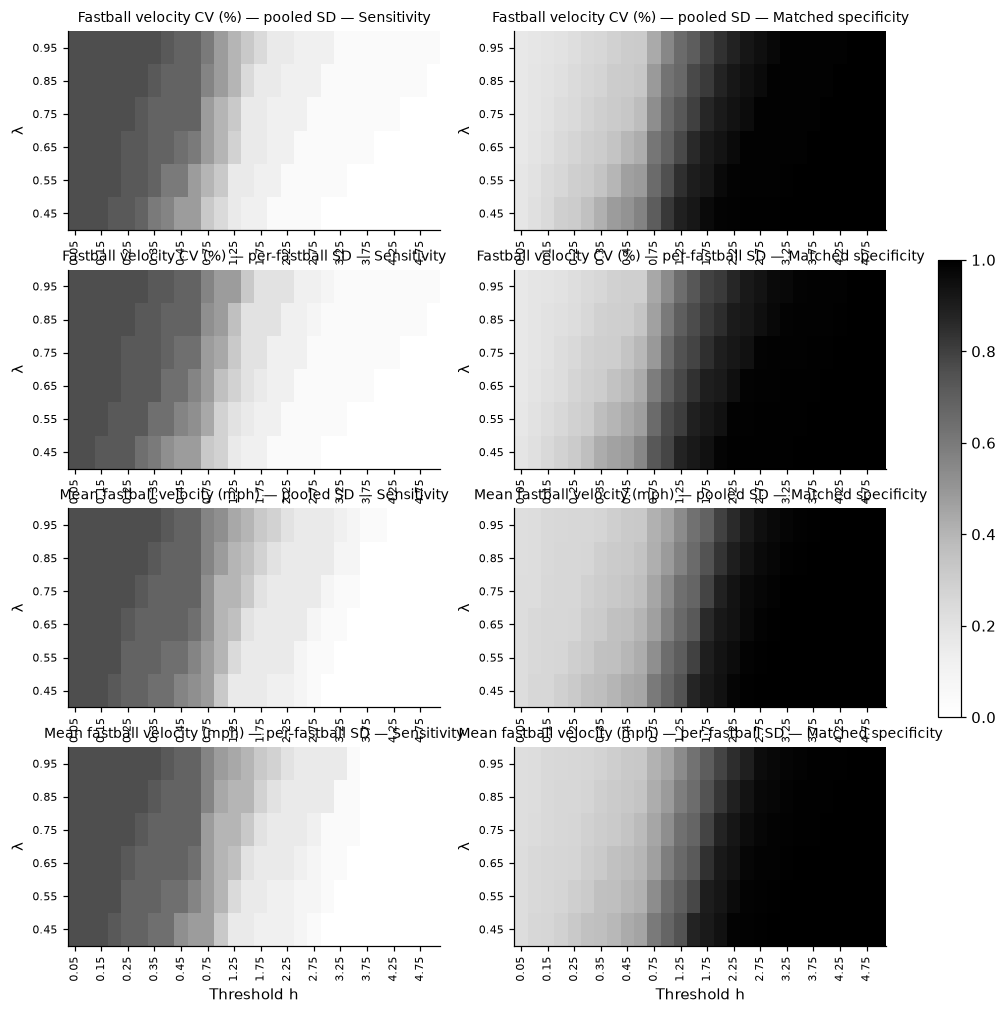

In [15]:
fig, axes = plt.subplots(len(CHARTS), 2, figsize=(12, 2.7 * len(CHARTS)), squeeze=False)
for row, key in enumerate(CHARTS):
    for col, measure in enumerate(["Sensitivity", "Matched_specificity"]):
        ax = axes[row, col]
        grid = train_grid.loc[train_grid["chart"] == key].pivot(index="lambda", columns="h", values=measure)
        im = ax.imshow(grid.to_numpy(float), cmap="Greys", vmin=0, vmax=1, aspect="auto", origin="lower")
        ax.set_xticks(range(0, len(grid.columns), 2), [f"{h:.2f}" for h in grid.columns[::2]], rotation=90, fontsize=7)
        ax.set_yticks(range(len(grid.index)), [f"{l:.2f}" for l in grid.index], fontsize=7)
        ax.grid(False)
        ax.set_title(f"{CHARTS[key]['label']} — {measure.replace('_', ' ')}", fontsize=9)
        ax.set_ylabel("λ")
        if row == len(CHARTS) - 1:
            ax.set_xlabel("Threshold h")
fig.colorbar(im, ax=axes, shrink=0.5)
save(fig, "E3_matched_grid_heatmaps")

### Block-bootstrap false-alarm check (matched exposure)

Synthetic in-control sequences are built from training units' own baseline games (standardized with the
frozen baseline, resampled in overlapping blocks of 3), each as long as a randomly chosen training
**case's** monitored series, so the exposure matches the matched specificity above. If the observed
matched false-positive rate (1 − matched specificity) is at or below the bootstrap rate, controls are not
alarming more often than chance on in-control data would explain.

In [16]:
rng = np.random.default_rng(SEED)
case_lengths = units.loc[(units["split"] == "train") & (units["case"] == 1), "monitored_games"].to_numpy()
null_rows = []
for key in CHARTS:
    pools = [unit_data[u]["baseline_dev"][key] for u in train_uids
             if len(unit_data[u]["baseline_dev"][key]) >= BLOCK_LEN]
    if not pools or not len(case_lengths):
        continue
    starts = [(i, s) for i, p in enumerate(pools) for s in range(len(p) - BLOCK_LEN + 1)]
    seqs = []
    for L in rng.choice(case_lengths, size=N_NULL_SEQUENCES):
        idx = rng.integers(len(starts), size=-(-int(L) // BLOCK_LEN))
        seqs.append(np.concatenate([pools[starts[j][0]][starts[j][1]:starts[j][1] + BLOCK_LEN] for j in idx])[:L])
    for lam in LAMBDA_GRID:
        pk = np.array([ewma_cusum(s, lam).max() for s in seqs])
        for h in H_GRID_WIDE:
            null_rows.append({"chart": key, "lambda": lam, "h": h, "bootstrap_false_alarm": (pk > h).mean()})
null_check = train_grid.merge(pd.DataFrame(null_rows), on=["chart", "lambda", "h"])
null_check["observed_false_positive_rate"] = 1 - null_check["Matched_specificity"]
null_check["at_or_below_bootstrap"] = null_check["observed_false_positive_rate"] <= null_check["bootstrap_false_alarm"] + 1e-12
null_check.to_csv(OUT_DIR / "block_bootstrap_false_alarm.csv", index=False)
display(null_check.groupby("chart")["at_or_below_bootstrap"].mean().rename("share of grid at or below bootstrap").round(3))
display(null_check.merge(chosen.reset_index()[["chart", "lambda", "h"]], on=["chart", "lambda", "h"])
                  [["chart", "lambda", "h", "observed_false_positive_rate", "bootstrap_false_alarm"]].round(3))

chart
cv|per_fb      0.673
cv|pooled      0.750
velo|per_fb    0.411
velo|pooled    0.482
Name: share of grid at or below bootstrap, dtype: float64

,chart,lambda,h,observed_false_positive_rate,bootstrap_false_alarm
0,cv|pooled,0.85,1.00,0.376,0.413
1,cv|per_fb,0.95,1.25,0.355,0.365
2,velo|pooled,0.85,3.00,0.024,0.003
3,velo|per_fb,0.95,3.25,0.022,0.003


### ROC frontier (matched, training seasons)

As in the NBA study: the Pareto frontier of the (λ, h) grid, anchored at (0, 0) and (1, 1), with the
trapezoidal area under it. Because the frontier picks the best (λ, h) at every false-positive rate, its
AUC is optimistic; the threshold-free matched AUC above is the fairer single number.

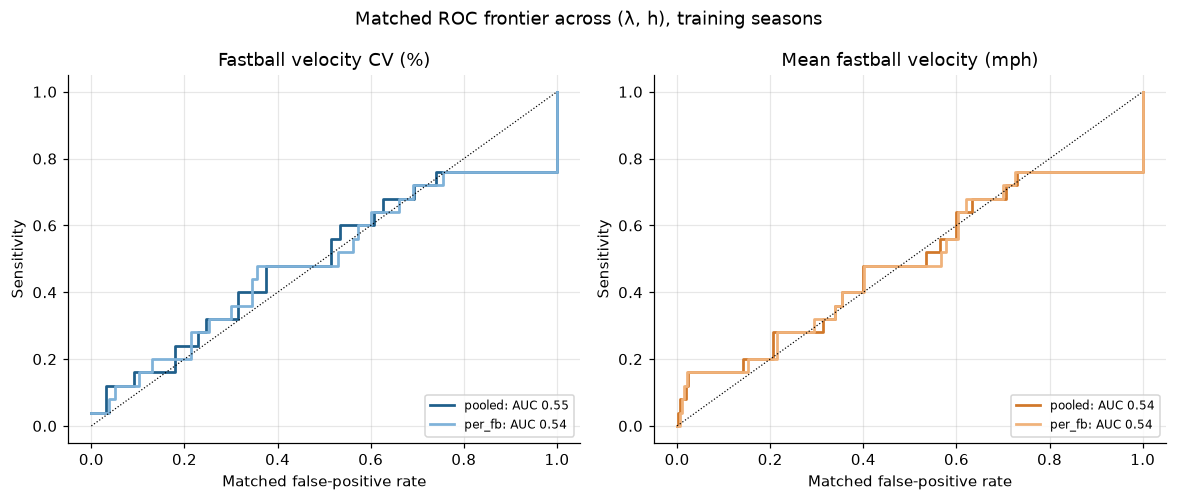

,chart,frontier_AUC
0,cv|pooled,0.550
1,cv|per_fb,0.539
2,velo|pooled,0.539
3,velo|per_fb,0.537


In [17]:
def roc_frontier(sens, fpr):
    pts = np.vstack([[0, 0], np.column_stack([fpr, sens]), [1, 1]])
    pts = pts[~np.isnan(pts).any(axis=1)]
    pts = pts[np.lexsort((-pts[:, 1], pts[:, 0]))]
    frontier, best = [], -1.0
    for x, y in pts:
        if y > best:
            frontier.append((x, y))
            best = y
    frontier = np.array(frontier)
    if frontier[-1, 0] < 1:
        frontier = np.vstack([frontier, [1, best]])
    area = np.trapezoid(frontier[:, 1], frontier[:, 0]) if hasattr(np, "trapezoid") else np.trapz(frontier[:, 1], frontier[:, 0])
    return frontier, area


fig, axes = plt.subplots(1, len(METRICS), figsize=(5.4 * len(METRICS), 4.6), squeeze=False)
roc_rows = []
for ax, m in zip(axes[0], METRICS):
    for key in [k for k in CHARTS if CHARTS[k]["stat"] == m]:
        g = train_grid.loc[train_grid["chart"] == key]
        frontier, area = roc_frontier(g["Sensitivity"].to_numpy(), 1 - g["Matched_specificity"].to_numpy())
        ax.step(frontier[:, 0], frontier[:, 1], where="post", lw=1.8, color=colors.get(key),
                label=f"{CHARTS[key]['mode']}: AUC {area:.2f}")
        roc_rows.append({"chart": key, "frontier_AUC": area})
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_xlabel("Matched false-positive rate")
    ax.set_ylabel("Sensitivity")
    ax.set_title(METRICS[m]["label"])
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Matched ROC frontier across (λ, h), training seasons")
fig.tight_layout()
save(fig, "E4_matched_roc")
pd.DataFrame(roc_rows).to_csv(OUT_DIR / "train_matched_roc_auc.csv", index=False)
display(pd.DataFrame(roc_rows).round(3))

## 10. Per-game analysis: does an alarm mean an elbow IL is near?

The matched comparison asks "does this pitcher's chart ever signal?". The per-game view asks the question
a team would face each day: **when the chart is in alarm after a game, is an elbow IL placement more
likely within the next `HAZARD_K` appearances?** Every monitored game of every training unit is one row:

* **alarm** = chart above h after that game (selected λ, h for each chart),
* **outcome** = the unit is a case and this game is one of his last `HAZARD_K` appearances before the
  subsequent elbow IL date.

Reported: the outcome rate after alarm games and after no-alarm games, their ratio (crude risk ratio),
and the **role-adjusted** (Mantel-Haenszel, stratified by starter / reliever / mixed) risk ratio, which is
the one to read: starters have fewer post-return games, so a larger share of their games fall in the
outcome window, and any role difference in alarm rates would otherwise show up as a false association.
Intervals resample pitchers.

In [18]:
def game_rows(uids, key, lam, h):
    out = []
    for u in uids:
        d = unit_data[u]
        path = ewma_cusum(d["dev"][key], lam)
        back = d["n_apps_before_stop"] - d["monitored"]["app_index"].to_numpy()    # 1 = final appearance
        case = units.at[u, "case"] == 1
        out.append(pd.DataFrame({"uid": u, "pkey": units.at[u, "pkey"], "role": units.at[u, "role"],
                                 "case": int(case), "games_before_stop": back, "alarm": path > h,
                                 "outcome": case & (back <= HAZARD_K)}))
    return pd.concat(out, ignore_index=True)


def risk_ratio(df):
    a = df.loc[df["alarm"], "outcome"]
    b = df.loc[~df["alarm"], "outcome"]
    ra, rb = (a.mean() if len(a) else np.nan), (b.mean() if len(b) else np.nan)
    return ra, rb, (ra / rb if rb and rb > 0 else np.nan)


ROLES = ["starter", "reliever", "mixed", "unknown"]


def _rr_from_tab(tab, w):
    """tab[g, r] = (alarm games, games, alarm & outcome, no-alarm & outcome) for pitcher g in role r."""
    T = np.einsum("g,grk->rk", w, tab)                 # weighted totals per role
    a_n, n, ao, no = T.sum(axis=0)
    pa = ao / a_n if a_n else np.nan
    pb = no / (n - a_n) if n - a_n else np.nan
    crude = pa / pb if pb and pb > 0 else np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        num = np.nansum(np.where(T[:, 1] > 0, T[:, 2] * (T[:, 1] - T[:, 0]) / T[:, 1], 0))
        den = np.nansum(np.where(T[:, 1] > 0, T[:, 3] * T[:, 0] / T[:, 1], 0))
    mh = num / den if den > 0 else np.nan
    return pa, pb, crude, mh


def risk_ratio_ci(df):
    """Crude and role-adjusted (Mantel-Haenszel) risk ratios; pitcher-clustered interval for the MH ratio."""
    groups = df["pkey"].unique()
    gi = {g: i for i, g in enumerate(groups)}
    tab = np.zeros((len(groups), len(ROLES), 4))
    for (g, r), x in df.groupby(["pkey", "role"]):
        tab[gi[g], ROLES.index(r)] += [x["alarm"].sum(), len(x), (x["alarm"] & x["outcome"]).sum(),
                                       (~x["alarm"] & x["outcome"]).sum()]
    pa, pb, crude, mh = _rr_from_tab(tab, np.ones(len(groups)))
    rng = np.random.default_rng(SEED)
    draws = [_rr_from_tab(tab, np.bincount(rng.integers(len(groups), size=len(groups)),
                                           minlength=len(groups)).astype(float))[3] for _ in range(N_BOOT)]
    draws = np.array(draws, float)
    lo, up = np.nanpercentile(draws, [2.5, 97.5]) if np.isfinite(draws).any() else (np.nan, np.nan)
    return {"p_alarm": pa, "p_no_alarm": pb, "RR_crude": crude, "RR_role_adjusted": mh,
            "RR_adj_lower95": lo, "RR_adj_upper95": up}


hazard_rows, per_game_tables = [], {}
for key, r in chosen.iterrows():
    df = game_rows(train_uids, key, r["lambda"], r["h"])
    per_game_tables[key] = df
    rr = risk_ratio_ci(df)
    hazard_rows.append({"chart": key, "lambda": r["lambda"], "h": r["h"], "games": len(df),
                        "alarm_games": int(df["alarm"].sum()), "outcome_games": int(df["outcome"].sum()),
                        f"P(elbow IL within {HAZARD_K} | alarm)": rr["p_alarm"],
                        f"P(elbow IL within {HAZARD_K} | no alarm)": rr["p_no_alarm"],
                        **{k: v for k, v in rr.items() if k.startswith("RR")}})
hazard = pd.DataFrame(hazard_rows)
hazard.to_csv(OUT_DIR / "per_game_alarm_risk_ratio.csv", index=False)
display(hazard.round(3))

,chart,lambda,h,games,alarm_games,outcome_games,P(elbow IL within 3 | alarm),P(elbow IL within 3 | no alarm),RR_crude,RR_role_adjusted,RR_adj_lower95,RR_adj_upper95
0,cv|per_fb,0.95,1.25,1635,197,52,0.046,0.030,1.528,1.517,0.538,3.072
1,cv|pooled,0.85,1.00,1635,238,52,0.046,0.029,1.575,1.571,0.455,3.548
2,velo|per_fb,0.95,3.25,1635,19,52,0.053,0.032,1.668,1.678,0.000,8.401
3,velo|pooled,0.85,3.00,1635,24,52,0.042,0.032,1.316,1.317,0.000,6.218


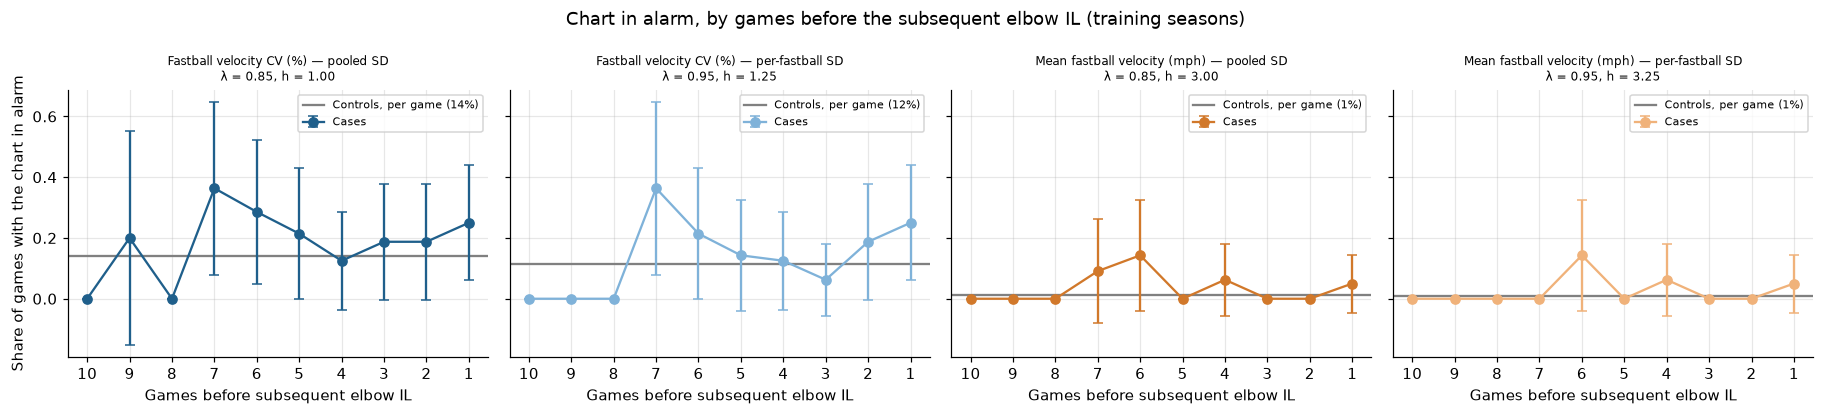

In [19]:
fig, axes = plt.subplots(1, len(CHARTS), figsize=(4.2 * len(CHARTS), 3.8), sharey=True, squeeze=False)
for ax, key in zip(axes[0], CHARTS):
    df = per_game_tables[key]
    cases = df.loc[df["case"] == 1]
    rate = cases.loc[cases["games_before_stop"] <= GAMES_BACK].groupby("games_before_stop")["alarm"].agg(["mean", "count"])
    rate = rate.reindex(range(1, GAMES_BACK + 1))
    half = 1.96 * np.sqrt(rate["mean"] * (1 - rate["mean"]) / rate["count"])
    ctrl_rate = df.loc[df["case"] == 0, "alarm"].mean()
    ax.axhline(ctrl_rate, color="grey", lw=1.5, label=f"Controls, per game ({ctrl_rate:.0%})")
    ax.errorbar(rate.index, rate["mean"], yerr=half, fmt="o-", capsize=3, color=colors.get(key), label="Cases")
    ax.invert_xaxis()
    ax.set_xticks(range(1, GAMES_BACK + 1))
    ax.set_xlabel("Games before subsequent elbow IL")
    ax.set_title(f"{CHARTS[key]['label']}\nλ = {chosen.loc[key, 'lambda']:.2f}, h = {chosen.loc[key, 'h']:.2f}", fontsize=8)
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("Share of games with the chart in alarm")
fig.suptitle("Chart in alarm, by games before the subsequent elbow IL (training seasons)")
fig.tight_layout()
save(fig, "E5_alarm_rate_by_games_before_IL")

### Honest training estimates: leave-one-season-out

The selected (λ, h) and the numbers above are scored on the same seasons used to pick them, out of
several hundred (chart, λ, h) combinations, so they are optimistic (on simulated data with **no** signal,
the in-sample risk ratio at a selected setting can come out well above 1). Here each training season is
left out in turn: (λ, h) is picked on the other training seasons by matched Youden and scored on the
left-out season (cases matched with controls from that season). The pooled results are the honest
training estimates; the threshold-free matched AUC in Section 9 involves no selection.

In [20]:
loso_rows, loso_games, loso_picks = [], [], []
for key in CHARTS:
    hits, specs, frames = [], [], []
    for season in TRAIN_SEASONS:
        fit_u = [u for u in train_uids if units.at[u, "Season"] != season]
        ev_u = [u for u in train_uids if units.at[u, "Season"] == season]
        grid = matched_grid(fit_u, key, LAMBDA_GRID, H_GRID_WIDE)
        if grid.empty:
            continue
        r = pick(grid).loc[key]
        loso_picks.append({"chart": key, "left_out": season, "lambda": r["lambda"], "h": r["h"]})
        cases, ctrls, case_peak, col, SV = pair_matrices(ev_u, key, r["lambda"])
        if SV is None:
            continue
        V = SV[1]
        use = V.any(axis=1)
        hits += list(case_peak[use] > r["h"])
        with np.errstate(invalid="ignore"):
            specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
        frames.append(game_rows(ev_u, key, r["lambda"], r["h"]))
    games = pd.concat(frames, ignore_index=True)
    rr = risk_ratio_ci(games)
    loso_rows.append({"chart": key, "cases": len(hits), "Sensitivity": np.mean(hits),
                      "Matched_specificity": np.mean(specs), "Youden": np.mean(hits) + np.mean(specs) - 1,
                      **{k: v for k, v in rr.items() if k.startswith("RR")}})
loso = pd.DataFrame(loso_rows)
loso.to_csv(OUT_DIR / "train_leave_one_season_out.csv", index=False)
pd.DataFrame(loso_picks).to_csv(OUT_DIR / "train_leave_one_season_out_picks.csv", index=False)
print("Leave-one-season-out (honest) training estimates:")
display(loso.round(3))
print("Settings picked in each fold (stable picks are reassuring):")
display(pd.DataFrame(loso_picks).pivot(index="left_out", columns="chart", values=["lambda", "h"]))

/tmp/ipykernel_28520/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_28520/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_28520/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_28520/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])


Leave-one-season-out (honest) training estimates:


,chart,cases,Sensitivity,Matched_specificity,Youden,RR_crude,RR_role_adjusted,RR_adj_lower95,RR_adj_upper95
0,cv|pooled,24,0.208,0.769,-0.022,1.117,1.107,0.154,2.958
1,cv|per_fb,24,0.250,0.744,-0.006,1.290,1.287,0.310,2.935
2,velo|pooled,24,0.042,0.972,0.014,0.000,0.000,0.000,0.000
3,velo|per_fb,24,0.083,0.972,0.056,0.000,0.000,0.000,0.000


Settings picked in each fold (stable picks are reassuring):


lambda                                           h            \
chart    cv|per_fb cv|pooled velo|per_fb velo|pooled cv|per_fb cv|pooled   
left_out                                                                   
2021          0.95      0.85        0.45        0.45      1.25       1.0   
2022          0.95      0.95        0.95        0.85      3.00       3.0   
2023          0.95      0.75        0.95        0.85      1.25       0.5   
2024          0.55      0.95        0.95        0.95      0.75       3.0   

                                  
chart    velo|per_fb velo|pooled  
left_out                          
2021            2.25        2.25  
2022            3.25        3.00  
2023            3.25        3.00  
2024            3.25        3.25

## 11. Starters and relievers separately

Matched AUC within each role (cases and controls of the same role only) at each chart's selected λ, and
the selected setting's matched sensitivity / specificity. Role comes from the year before the initial
injury: share of games started ≥ 0.6 → starter, ≤ 0.2 → reliever, otherwise mixed.

In [21]:
role_rows = []
for key, r in chosen.iterrows():
    for role in ["starter", "reliever", "mixed"]:
        a = matched_auc(train_uids, key, r["lambda"], role=role)
        g = matched_grid(train_uids, key, [r["lambda"]], [r["h"]], role=role)
        role_rows.append({"chart": key, "role": role, "lambda": r["lambda"], "h": r["h"], **a,
                          "Sensitivity": g["Sensitivity"].iat[0] if len(g) else np.nan,
                          "Matched_specificity": g["Matched_specificity"].iat[0] if len(g) else np.nan})
by_role = pd.DataFrame(role_rows)
by_role.to_csv(OUT_DIR / "train_by_role.csv", index=False)
display(by_role.round(3))

,chart,role,lambda,h,cases,controls,AUC,lower95,upper95,Sensitivity,Matched_specificity
0,cv|per_fb,starter,0.95,1.25,9,53,0.560,0.325,0.804,0.444,0.781
1,cv|per_fb,reliever,0.95,1.25,15,65,0.457,0.290,0.611,0.467,0.566
2,cv|per_fb,mixed,0.95,1.25,1,7,1.000,1.000,1.000,1.000,0.600
3,cv|pooled,starter,0.85,1.00,9,53,0.549,0.316,0.792,0.444,0.749
4,cv|pooled,reliever,0.85,1.00,15,65,0.454,0.291,0.610,0.467,0.552
5,cv|pooled,mixed,0.85,1.00,1,7,1.000,1.000,1.000,1.000,0.600
6,velo|per_fb,starter,0.95,3.25,9,53,0.522,0.281,0.742,0.222,0.975
7,velo|per_fb,reliever,0.95,3.25,15,65,0.461,0.290,0.642,0.067,0.978
8,velo|per_fb,mixed,0.95,3.25,1,7,1.000,1.000,1.000,1.000,1.000
9,velo|pooled,starter,0.85,3.00,9,53,0.537,0.295,0.758,0.222,0.975


## 12. Example control charts (training seasons)

For each chart at its selected (λ, h): one case whose chart signalled and the control with the median
peak. **Top:** game value with $\mu_0$ and $\mu_0 \pm 2\sigma$ ($\sigma$ varies by game in the per-fastball
version). **Bottom:** the EWMA-CUSUM with h; orange = subsequent elbow IL.

In [ ]:
for key, r in chosen.iterrows():
    lam, h, m = r["lambda"], r["h"], CHARTS[key]["stat"]
    signalled = [u for u in train_cases if ewma_cusum(unit_data[u]["dev"][key], lam).max() > h]
    case_uid = signalled[0] if signalled else (train_cases[0] if train_cases else None)
    pk = {u: ewma_cusum(unit_data[u]["dev"][key], lam).max() for u in train_ctrls}
    ctrl_uid = min(pk, key=lambda u: abs(pk[u] - np.median(list(pk.values())))) if pk else None
    examples = [u for u in (case_uid, ctrl_uid) if u is not None]
    if not examples:
        continue
    fig, axes = plt.subplots(2, len(examples), figsize=(6 * len(examples), 6), sharex="col", squeeze=False,
                             gridspec_kw={"height_ratios": [1.2, 1]})
    for col, u in enumerate(examples):
        d, row = unit_data[u], units.loc[u]
        mon = d["monitored"]
        x = np.arange(1, len(mon) + 1)
        top, bot = axes[0, col], axes[1, col]
        mu0, sig = d["mu0"][m], d["sigma"][key]
        top.plot(x, mon[m], "o-", color="#1f5f8b", ms=4)
        top.plot(x, np.full(len(x), mu0), color="black", lw=1, label="μ₀ (shrunk baseline)")
        top.plot(x, mu0 + 2 * sig, color="black", ls="--", lw=0.8, label="μ₀ ± 2σ")
        top.plot(x, mu0 - 2 * sig, color="black", ls="--", lw=0.8)
        path = ewma_cusum(d["dev"][key], lam)
        bot.step(x, path, where="mid", color="#1f5f8b")
        bot.axhline(h, color="red", ls="--", lw=1, label=f"h = {h:.2f}")
        over = np.flatnonzero(path > h)
        if len(over):
            for axis in (top, bot):
                axis.axvline(over[0] + 1, color="red", alpha=0.5)
        if row["case"]:
            for axis in (top, bot):
                axis.axvline(len(x) + 0.5, color="darkorange", lw=2, label="Subsequent elbow IL" if axis is bot else None)
        kind = "Case" if row["case"] else "Control"
        top.set_title(f"{kind}: {row['Name']} {row['Season']} ({row['role']})\ninitial: {row['initial_injury']}"
                      + (f" | next: {row['next_injury']}" if isinstance(row["next_injury"], str) else ""), fontsize=9)
        top.set_ylabel(METRICS[m]["label"])
        bot.set_ylabel("EWMA-CUSUM" + (" (lower side, sign-flipped)" if METRICS[m]["side"] == "lower" else ""))
        bot.set_xlabel("Monitored game since return")
        top.legend(fontsize=7)
        bot.legend(fontsize=7)
    fig.suptitle(f"{CHARTS[key]['label']}: λ = {lam:.2f}, h = {h:.2f}")
    fig.tight_layout()
    save(fig, f"E6_example_chart_{key.replace('|', '_')}")

## 13. Held-out season (off by default)

Set `RUN_HELDOUT = True` in the Settings cell **only once the design is final**. The frozen baselines and
each chart's selected (λ, h) are applied once to the held-out season: matched sensitivity / specificity,
matched AUC with pitcher-clustered intervals, the per-game risk ratio, and lead times.

In [ ]:
def wilson(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


if not RUN_HELDOUT:
    print(f"Held-out season {TEST_SEASON} not evaluated (RUN_HELDOUT = False).")
else:
    test_cases = [u for u in test_uids if units.at[u, "case"] == 1]
    rows, leads = [], []
    for key, r in chosen.iterrows():
        lam, h = r["lambda"], r["h"]
        g = matched_grid(test_uids, key, [lam], [h])
        a = matched_auc(test_uids, key, lam)
        rr = risk_ratio_ci(game_rows(test_uids, key, lam, h))["RR_role_adjusted"]
        n_c = int(g["cases"].iat[0]) if len(g) else 0
        sens = g["Sensitivity"].iat[0] if len(g) else np.nan
        sl, su = wilson(round(sens * n_c), n_c) if n_c else (np.nan, np.nan)
        rows.append({"chart": key, "lambda": lam, "h": h, "cases": n_c, "Sensitivity": sens,
                     "Sens 95% CI": f"{sl:.2f}–{su:.2f}",
                     "Matched_specificity": g["Matched_specificity"].iat[0] if len(g) else np.nan,
                     "matched_AUC": a["AUC"], "AUC 95% CI": f"{a['lower95']:.2f}–{a['upper95']:.2f}",
                     "per_game_RR_role_adjusted": rr})
        for u in test_cases:
            d = unit_data[u]
            over = np.flatnonzero(ewma_cusum(d["dev"][key], lam) > h)
            if len(over):
                game = d["monitored"].iloc[over[0]]
                leads.append({"chart": key, "Name": units.at[u, "Name"],
                              "lead_games": d["n_apps_before_stop"] - int(game["app_index"]),
                              "lead_days": (units.at[u, "event_date"] - game["game_date"]).days})
    heldout = pd.DataFrame(rows)
    heldout.to_csv(OUT_DIR / "heldout_evaluation.csv", index=False)
    display(heldout.round(3))
    lead = pd.DataFrame(leads, columns=["chart", "Name", "lead_games", "lead_days"])
    lead.to_csv(OUT_DIR / "heldout_lead_time.csv", index=False)
    if len(lead):
        display(lead.groupby("chart")[["lead_games", "lead_days"]].agg(["count", "median"]))

## 14. Notes for interpretation

* **Read Section 7 and the permutation test first.** If neither statistic moves before a subsequent
  elbow IL (Section 7) and the permutation p-value is large, tuning h will not rescue the chart.
* **Selected settings are optimistic.** Numbers at the selected (λ, h) are scored on the data used to
  pick them. Use the leave-one-season-out estimates (end of Section 10) and the matched AUC instead.
* **Small numbers.** With about 25 training cases, a sensitivity of 0.5 has a 95% interval of roughly
  0.3–0.7; differences between neighbouring (λ, h) settings are mostly noise.
* **Same pitcher, several seasons.** Matched AUC and risk-ratio intervals resample pitchers; the
  sensitivity / specificity point estimates treat units as independent, as in the NBA study.
* **The IL date is not the injury date.** A signal in the final game is closer to detection than warning.
* **CV and mean velocity answer different questions.** CV divides out the level (consistency); the mean
  tracks the level. The replication notebook found the arm signal in the level.
* **Things to vary** (Settings): `CV_FIRST_N` (e.g. 20, to put starters and relievers on the same footing),
  `MIN_FB_GAME`, `HAZARD_K`, and the elbow pattern.